# Лабораторная работа № 5. Классификация

Вариант 1. По данным `medical_diagnosis.csv` предсказываем класс `Disease` (0 — пациент не болеет, 1 — болеет). Сравниваем метод k-ближайших соседей, дерево решений, логистическую регрессию и случайный лес.

## Загрузка данных

Проверим размер таблицы, пропуски и полные дубликаты.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
DATA_PATH = Path("data/medical_diagnosis.csv")
IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")

target = "Disease"
data = pd.read_csv(DATA_PATH)
print(f"Размер таблицы: {data.shape[0]} строк, {data.shape[1]} столбцов")
print(f"Пропусков: {int(data.isna().sum().sum())}")
print(f"Полных дубликатов: {int(data.duplicated().sum())}")
display(data.head())

Размер таблицы: 3031 строк, 14 столбцов
Пропусков: 0
Полных дубликатов: 1


,age,sex,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,smoking_status,family_history,activity_level,symptom_score,CRP_mg_L,WBC_10e9_L,ECG_result,Disease
0,34,Male,16.8,132.0,196.0,78.0,Current,No,High,0.2,0.58,8.60,Normal,0
1,24,Female,29.2,118.0,182.0,96.0,Current,No,Moderate,3.2,2.72,6.54,Normal,0
2,19,Female,16.5,121.0,268.0,101.0,Current,No,Moderate,3.8,0.18,6.61,Normal,0
3,89,Female,15.4,117.0,136.0,96.0,Never,No,Low,2.6,1.83,5.67,Normal,0
4,66,Male,16.7,82.0,241.0,126.0,Former,No,Moderate,3.5,1.16,2.66,Normal,0


## Очистка данных

В конце файла у 31 записи одновременно повышены холестерин и С-реактивный белок (СРБ). Проверим, есть ли для каждой записи исходная строка, у которой совпадают все остальные поля, а изменённые значения получаются по формулам `холестерин × 1,8 + 120` и `СРБ × 3,5 + 20`. Удалим полные дубликаты и копии, для которых нашлась такая пара.

Изменённых копий после удаления полных дубликатов: 30
После очистки: 3000 записей


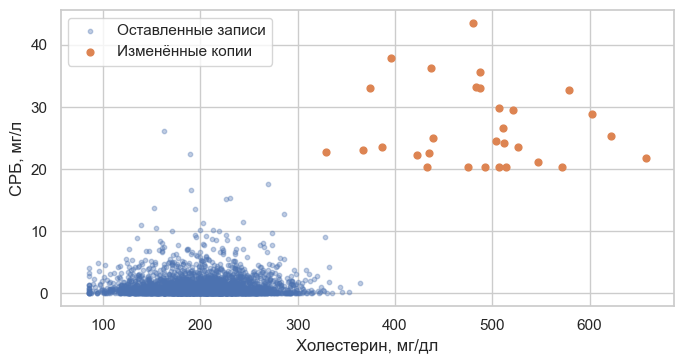

In [2]:
cholesterol = "cholesterol_mg_dl"
crp = "CRP_mg_L"
unique_data = data.drop_duplicates()
unchanged_columns = unique_data.columns.difference([cholesterol, crp]).tolist()

pairs = unique_data.reset_index(names="row").merge(
    unique_data,
    on=unchanged_columns,
    suffixes=("_copy", "_original"),
)
matches = (
    np.isclose(pairs[f"{cholesterol}_copy"], 1.8 * pairs[f"{cholesterol}_original"] + 120)
    & np.isclose(pairs[f"{crp}_copy"], 3.5 * pairs[f"{crp}_original"] + 20)
)
modified_rows = unique_data.index.isin(pairs.loc[matches, "row"])
clean_data = unique_data.loc[~modified_rows].reset_index(drop=True)

print(f"Изменённых копий после удаления полных дубликатов: {modified_rows.sum()}")
print(f"После очистки: {len(clean_data)} записей")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(clean_data[cholesterol], clean_data[crp], s=10, alpha=0.35, label="Оставленные записи")
ax.scatter(
    unique_data.loc[modified_rows, cholesterol],
    unique_data.loc[modified_rows, crp],
    s=24,
    label="Изменённые копии",
)
ax.set(xlabel="Холестерин, мг/дл", ylabel="СРБ, мг/л")
ax.legend()
fig.tight_layout()
fig.savefig(IMAGE_DIR / "data_audit.png", dpi=180)
plt.show()

## Диаграммы рассеяния и баланс классов

Строим матрицу рассеяния для восьми числовых признаков по всем очищенным записям. Значение `Disease` определяет цвет точек.

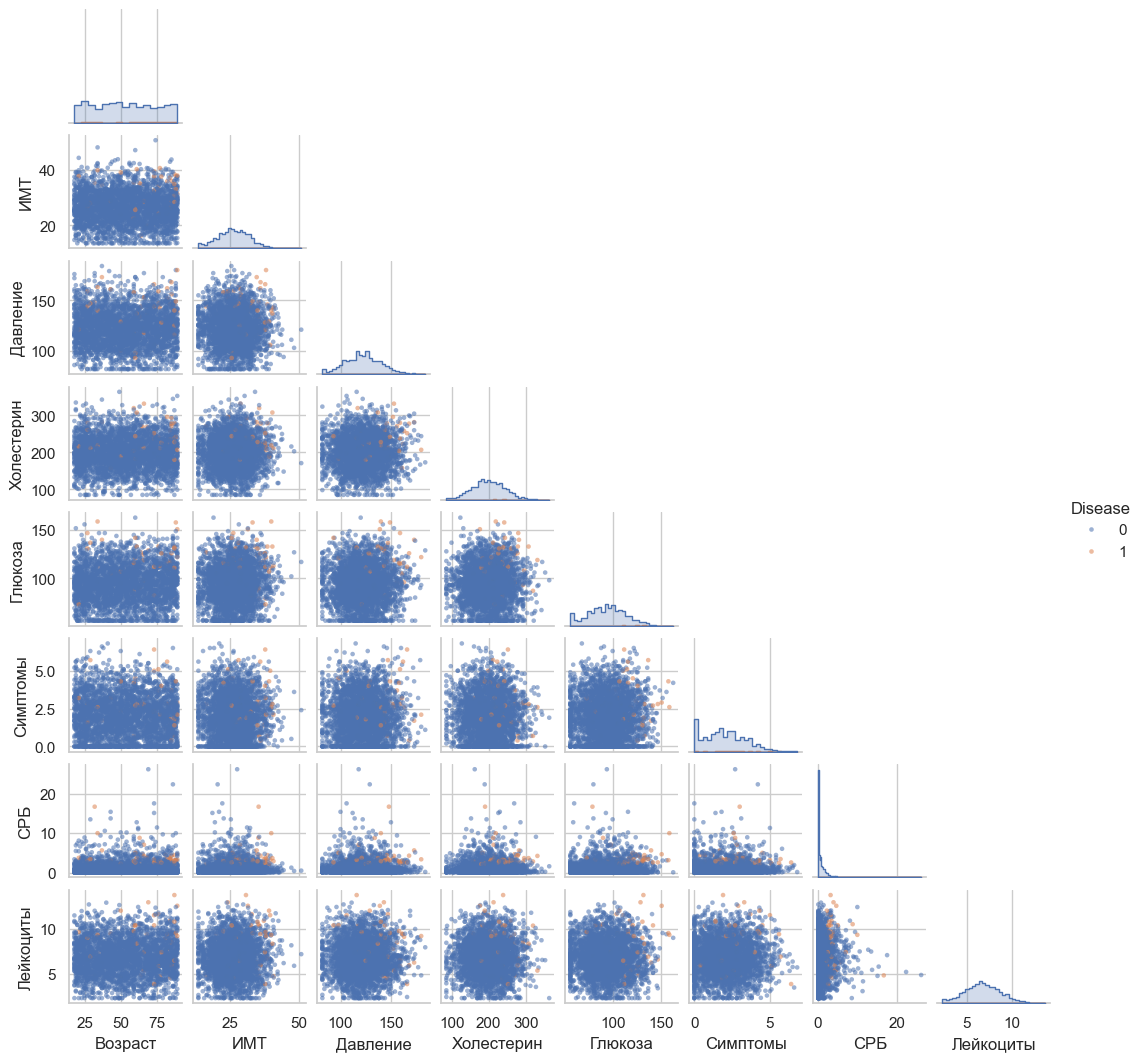

,Количество,"Доля, %"
Disease,,
0,2952,98.4
1,48,1.6


In [3]:
X = clean_data.drop(columns=target)
y = clean_data[target]
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

plot_labels = {
    "age": "Возраст",
    "BMI": "ИМТ",
    "systolic_bp": "Давление",
    "cholesterol_mg_dl": "Холестерин",
    "fasting_glucose_mg_dl": "Глюкоза",
    "symptom_score": "Симптомы",
    "CRP_mg_L": "СРБ",
    "WBC_10e9_L": "Лейкоциты",
}
pair_plot = sns.pairplot(
    clean_data.rename(columns=plot_labels),
    vars=list(plot_labels.values()),
    hue=target,
    hue_order=[0, 1],
    corner=True,
    diag_kind="hist",
    plot_kws={"s": 11, "alpha": 0.55, "linewidth": 0},
    diag_kws={"element": "step", "common_norm": False},
    height=1.35,
)
pair_plot.savefig(IMAGE_DIR / "pairplot.png", dpi=180)
plt.show()

class_counts = y.value_counts().sort_index()
display(pd.DataFrame({
    "Количество": class_counts,
    "Доля, %": (100 * class_counts / len(y)).round(1),
}))

## Подготовка выборок

На класс 1 приходится 1,6 % записей. Стратификация сохраняет близкие доли классов при разбиении 80:20. Оставляем исходное соотношение классов при обучении и проверяем, сколько положительных объектов нашли модели.

`StandardScaler` стандартизирует числовые признаки, `OneHotEncoder` кодирует категориальные. В каждом конвейере преобразования настраиваются на обучающей выборке.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

display(pd.DataFrame({
    "Обучающая выборка": y_train.value_counts().sort_index(),
    "Тестовая выборка": y_test.value_counts().sort_index(),
}))

,Обучающая выборка,Тестовая выборка
Disease,,
0,2362,590
1,38,10


## Обучение и оценка моделей

Обучаем четыре классификатора на одной выборке. Precision, Recall и F1 считаем для класса 1. ROC AUC рассчитываем по оценкам вероятности класса 1.

In [5]:
models = {
    "k-ближайших соседей": KNeighborsClassifier(n_neighbors=5),
    "Дерево решений": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Логистическая регрессия": LogisticRegression(max_iter=1000),
    "Случайный лес": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
}

predictions = {}
probabilities = {}
metric_rows = []

for name, estimator in models.items():
    model = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", estimator),
    ])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]
    predictions[name] = y_pred
    probabilities[name] = y_score
    metric_rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_score),
    })

metrics_table = pd.DataFrame(metric_rows).set_index("Модель")
display(metrics_table.round(3))

,Accuracy,Precision,Recall,Balanced accuracy,F1,ROC AUC
Модель,,,,,,
k-ближайших соседей,0.987,1.000,0.2,0.600,0.333,0.792
Дерево решений,0.968,0.154,0.2,0.591,0.174,0.591
Логистическая регрессия,0.985,0.667,0.2,0.599,0.308,0.985
Случайный лес,0.987,1.000,0.2,0.600,0.333,0.984


## Матрицы ошибок и ROC-кривые

В матрицах строки соответствуют истинным классам, столбцы — предсказанным. ROC-кривые четырёх моделей построены на общем графике.

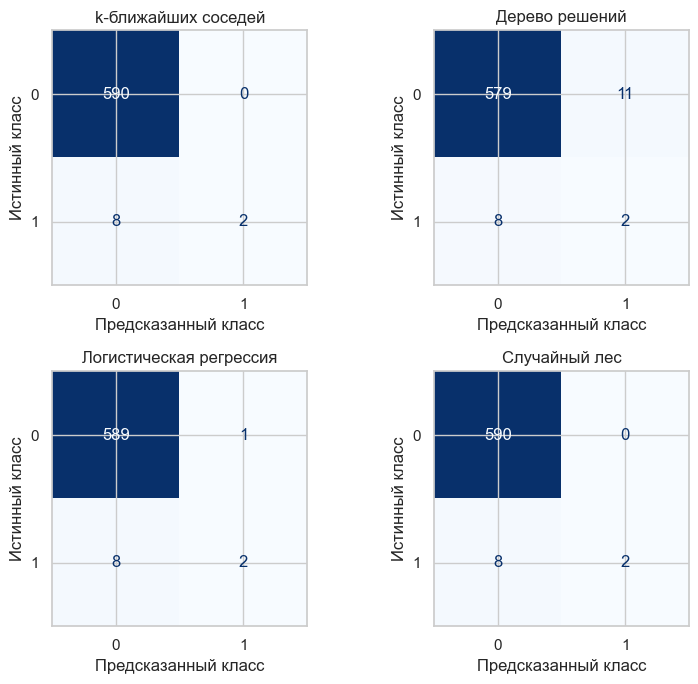

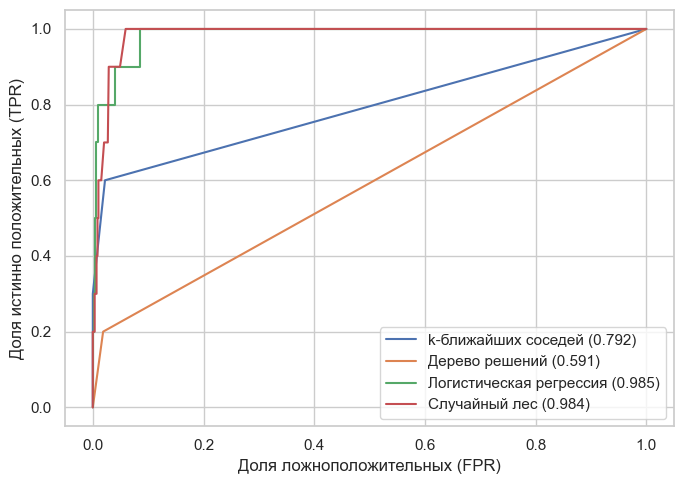

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for ax, (name, y_pred) in zip(axes.flat, predictions.items()):
    matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay(matrix).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set(title=name, xlabel="Предсказанный класс", ylabel="Истинный класс")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "confusion_matrices.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for name, y_score in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc_value = metrics_table.loc[name, "ROC AUC"]
    ax.plot(fpr, tpr, label=f"{name} ({auc_value:.3f})")
ax.set(xlabel="Доля ложноположительных (FPR)", ylabel="Доля истинно положительных (TPR)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "roc_curves.png", dpi=180)
plt.show()

## Вывод

Каждая модель нашла 2 из 10 положительных записей (Recall = 0,200). У метода k-ближайших соседей и случайного леса нет ложноположительных ответов, поэтому у них наибольшая F1 (0,333). Логистическая регрессия показала наибольший ROC AUC (0,985), но при стандартном правиле классификации также пропустила 8 случаев класса 1. При постоянном предсказании класса 0 Accuracy составила бы 590/600, или 98,33 %. Поэтому высокая Accuracy здесь объясняется главным образом преобладанием класса 0.